## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

48691
48691


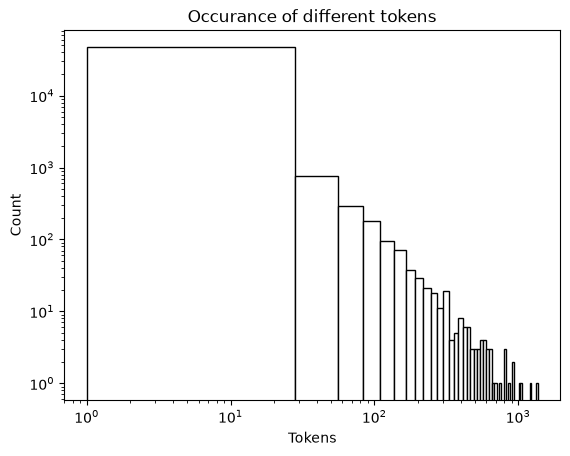

Training R²: 0.7692270058094296
Test R²: 0.654018807982767
Top 10 words by absolute coefficient:
background-image:   -0.887926
localized            0.796073
rhythm               0.624596
cnet                -0.543767
thermal              0.541448
group:               0.528332
xanaax               0.522881
rcs                  0.518453
#331f30;             0.510378
#000000;             0.510378
dtype: float64


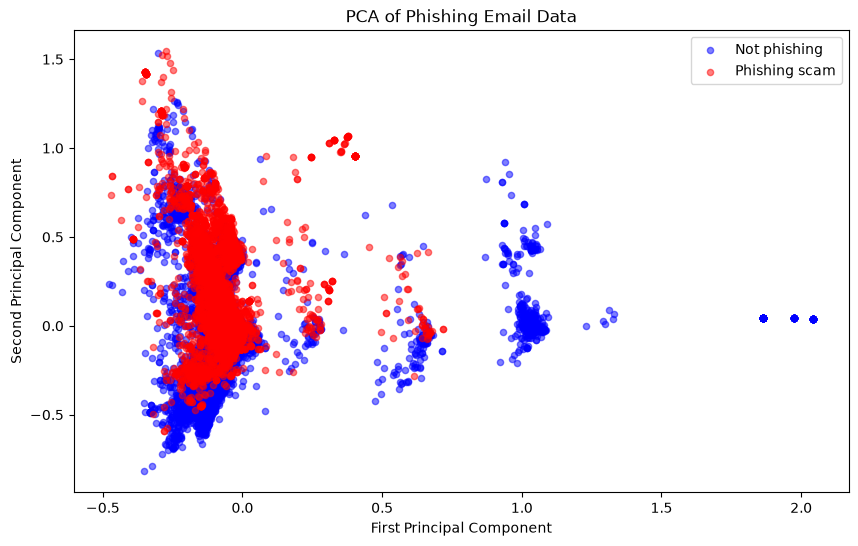

Explained variance ratio: [0.01113091 0.0086119 ]
Total variance explained: 0.019742809352879042


In [ ]:
# Your Phase 1 solution to the problem goes here.
#**Q1.**

# **Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing 
# is primarily about analyzing the frequency and co-occurrence of tokens.

# We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). 
# Run the below code chunk to open it, and use the Counter class to look at the most common words:

import pickle
#%pip install pandas
import pandas as pd
#%pip install matplotlib
import matplotlib.pyplot as plt
#%pip install numpy 
#%pip install pyarrow
import pyarrow as pa
#%pip install fastparquet
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA




with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
print(len(token_count))
token_freq = token_count.most_common()
print(len(token_freq))


# Plot a histogram of the occurrences of tokens. 
# What do you notice about the frequency of occurrence of different tokens? How does it look?
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins= 50, edgecolor='black', color='white')
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.xscale('log')
plt.yscale('log')
plt.title('Occurance of different tokens')
plt.show()

#**Q2.** 

# Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens 
# and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a
# scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

df = pd.read_parquet('data/Phishing_clean.parquet')
df.head()


#1. Perform an 80/20 train-test split of the data.

#looks like "Email Type" is the target and everything else are features
features = df.drop('Email Type', axis=1)
target = df['Email Type']
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2,)



#2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?

model = LinearRegression()
model.fit(features_train, target_train)
target_train_pred = model.predict(features_train)
target_test_pred = model.predict(features_test)
print("Training R²:", r2_score(target_train, target_train_pred))
print("Test R²:", r2_score(target_test, target_test_pred))

# Training R²: 0.7676772268579435
# Test R²: 0.6573000214443183

#3. What words have the largest coefficients in absolute value and most strongly influence predictions? 
coefficients = pd.Series(model.coef_, index=features.columns)

top_words = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index)

print("Top 10 words by absolute coefficient:")
print(top_words.head(10))
# Top 10 words are: 
# background-image:, localized, thermal, helvetica,, aging
# xanaax, cnet, intervention, form., arial,  

#**Q3.** 

# Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and 
# perform a principal components analysis decomposition with two components. Plot the first two principal components 
# in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

pca = PCA(n_components=2)
features_pca = pca.fit_transform(features)

pca_df = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = target.to_numpy()

plt.figure(figsize=(10, 6))

for email_type, label, color in [
    (0, 'Not phishing', 'blue'),
    (1, 'Phishing scam', 'red')
]:
    subset = pca_df[pca_df['Email Type'] == email_type]
    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=label,
        color=color,
        alpha=0.5,
        s=20
    )

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Phishing Email Data')
plt.legend()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

# Explained variance ratio: [0.0111309  0.00861162]
# Total variance explained: 0.01974251952778723
# The first two principal components explain only a small proportion of the variation in the data. 
# The phishing and non-phishing emails overlap substantially in the plot, with no clear separation between the two groups.



In [ ]:
#**Q4.**

#Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
#How does this performance compare to the linear regression?

pca = PCA(n_components=2610)
features_train_pca = pca.fit_transform(features_train)
features_test_pca = pca.transform(features_test)
pca_model = LinearRegression()
pca_model.fit(features_train_pca, target_train)
target_train_pred_pca = pca_model.predict(features_train_pca)
target_test_pred_pca = pca_model.predict(features_test_pca)


print("PCA Training R²:", r2_score(target_train, target_train_pred_pca))
print("PCA Test R²:", r2_score(target_test, target_test_pred_pca))
print("Total variance explained by 2610 components:",pca.explained_variance_ratio_.sum())

#PCA Training R²: 0.7685662368284408
#PCA Test R²: 0.6546399090060679
#Total variance explained by 2610 components: 0.9998611733085552

# The two models perform similarly. PCA has a slightly higher training R² but a slightly lower test R². 
# The 2,610 components retain about 99.986% of the original variance, so very little variance is lost.


#**Q5.**

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression,
# rather than the original data.

#PCA combines the original features into a smaller set of uncorrelated variables. 
# This can reduce redundancy and make high-dimensional regression easier to work with. 
# In this example, the PCA model performs similarly to the original regression, but it does not improve test performance. 
# Since 2,610 components retain almost all the original variance, the reduction is small. 
# The components are also harder to interpret than the original word features.




PCA Training R²: 0.7685662368284408
PCA Test R²: 0.6546399090060679
Total variance explained by 2610 components: 0.9998611733085552


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]